# Module 2 · A CNN looks at my field
This notebook uses **your** `src/cnn.py` (built with Claude from `docs/cnn_spec.md`).
Put **three photos from your own professional or academic field** in `data/my_field/` (jpg or png), then run it top to bottom.
The figure it saves, `results/my_field_cnn.png`, goes into Assignment 2.1. What you conclude from it is **yours**.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)

import glob
import numpy as np, matplotlib.pyplot as plt
from PIL import Image
from src import cnn
PHOTOS = sorted(p for p in glob.glob("data/my_field/*") if p.lower().endswith((".jpg", ".jpeg", ".png")))
if len(PHOTOS) < 3:
    print("WARNING: put three photos of YOUR field in data/my_field/. Using the course samples for now.")
    PHOTOS = ["data/m2_samples/pothole.png", "data/m2_samples/street.jpg"]
print(PHOTOS)

['data/my_field\\bottle_1.jpg', 'data/my_field\\bottle_2.jpg', 'data/my_field\\bottle_3.jpg']


## 1. Check your paper sketch
The small CNN of the class activity, traced by your code. Compare every size with your drawing.

In [2]:
for r in cnn.trace(cnn.small_cnn()):
    print(f"{r['layer']:18s} {str(r['shape']):16s} {r['weights']:6d} weights")
print("total:", sum(r["weights"] for r in cnn.trace(cnn.small_cnn())), "weights  |",
      cnn.count_parameters(cnn.small_cnn()), "with biases")
print("one 224 photo through the first layer of ResNet-18:", cnn.output_size(224, 7, padding=3, stride=2))

input              (64, 64, 3)           0 weights
Conv2d             (64, 64, 8)         216 weights
ReLU               (64, 64, 8)           0 weights
MaxPool2d          (32, 32, 8)           0 weights
Conv2d             (32, 32, 16)       1152 weights
ReLU               (32, 32, 16)          0 weights
MaxPool2d          (16, 16, 16)          0 weights
AdaptiveAvgPool2d  (1, 1, 16)            0 weights
Flatten            (16,)                 0 weights
Linear             (2,)                 32 weights
total: 1400 weights  | 1426 with biases
one 224 photo through the first layer of ResNet-18: 112


## 2. What a real network answers, sees and looks at
The first run downloads ResNet-18 (45 MB) once.

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\TUF/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


  0%|          | 0.00/44.7M [00:00<?, ?B/s]

  0%|          | 40.0k/44.7M [00:00<02:25, 321kB/s]

  0%|          | 152k/44.7M [00:00<01:07, 695kB/s] 

  1%|          | 240k/44.7M [00:00<01:16, 611kB/s]

  1%|          | 336k/44.7M [00:00<01:04, 717kB/s]

... (149 outputs left out)

ResNet-18: 11,689,512 parameters


data/my_field\bottle_1.jpg → water bottle 0.89, water jug 0.11, nipple 0.00


data/my_field\bottle_2.jpg → water bottle 0.77, perfume 0.11, water jug 0.07


data/my_field\bottle_3.jpg → water bottle 0.80, pop bottle 0.15, beer bottle 0.02


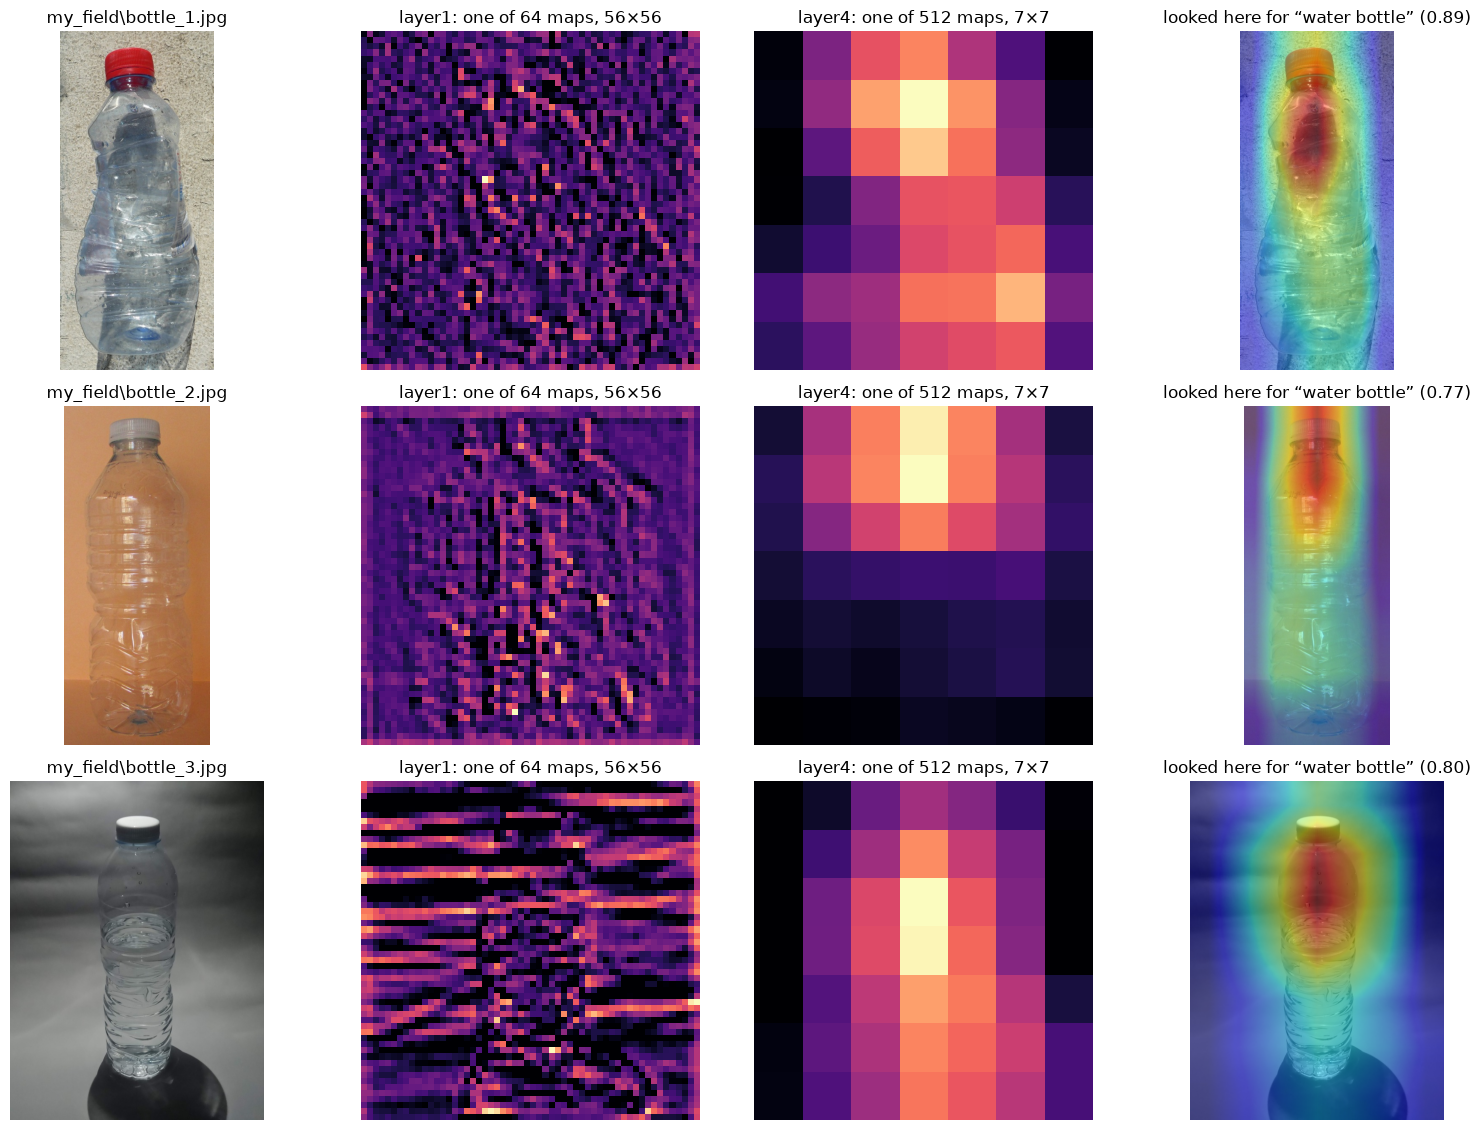

In [3]:
model, preprocess, categories = cnn.load_resnet()
print(f"ResNet-18: {cnn.count_parameters(model):,} parameters")
fig, axes = plt.subplots(len(PHOTOS), 4, figsize=(16, 3.8 * len(PHOTOS)), squeeze=False)
for row, path in zip(axes, PHOTOS):
    rgb = np.array(Image.open(path).convert("RGB"))
    top3 = cnn.classify(model, preprocess, categories, rgb, top=3)
    heat, k, p = cnn.gradcam(model, preprocess, rgb)
    l1 = cnn.feature_maps(model, preprocess, rgb, "layer1"); l4 = cnn.feature_maps(model, preprocess, rgb, "layer4")
    row[0].imshow(rgb); row[0].set_title(path.split("/")[-1])
    row[1].imshow(l1[l1.reshape(64, -1).std(1).argmax()], cmap="magma"); row[1].set_title("layer1: one of 64 maps, 56×56")
    row[2].imshow(l4[l4.reshape(512, -1).mean(1).argmax()], cmap="magma"); row[2].set_title("layer4: one of 512 maps, 7×7")
    row[3].imshow(cnn.overlay(rgb, heat)); row[3].set_title(f"looked here for “{categories[k]}” ({p:.2f})")
    for ax in row: ax.axis("off")
    print(path, "→", ", ".join(f"{n} {q:.2f}" for n, q in top3))
plt.tight_layout(); os.makedirs("results", exist_ok=True); plt.savefig("results/my_field_cnn.png", dpi=120); plt.show()

## My reading

### 1. Prediction confidence
The first image received the highest prediction confidence, with 89% confidence for the water bottle class. The second image received 77%, while the third received 80%. Although all three images were classified as water bottles, the confidence levels varied depending on the image.

### 2. Feature maps and Grad-CAM visualization
The Grad-CAM heatmaps mainly highlight the bottles, particularly their central and upper regions. This suggests that these areas contribute to the model's water bottle predictions. The layer 1 feature maps show more detailed visual patterns, while the layer 4 feature maps present more abstract and spatially compressed representations.

### 3. Model limitations
One important limitation is that the model may rely primarily on visual appearance rather than understanding the material or recyclability of an object. Its prediction of water bottle does not establish that it can identify plastic materials or determine whether an object is recyclable. Therefore, a pretrained image classifier should not be treated as a specialized plastic-waste detection system.